In [23]:
#1
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/ub_pm25_daily.csv", parse_dates=["date"])
df.head()

,date,pm25,coverage,station,group,sensor_id
0,2016-01-30,298.0,67.0,US Embassy,A,4686
1,2016-01-31,417.0,100.0,US Embassy,A,4686
2,2016-02-01,516.0,100.0,US Embassy,A,4686
3,2016-02-02,424.0,100.0,US Embassy,A,4686
4,2016-02-03,314.0,100.0,US Embassy,A,4686


In [24]:
#2
print(df["pm25"].describe())
print(df["coverage"].describe())
print("Negative values:", (df["pm25"] < 0).sum())
print("Over 1000:", (df["pm25"] > 1000).sum())

count    9590.000000
mean       74.470136
std        91.356574
min         0.000000
25%        18.400000
50%        37.800000
75%        96.575000
max       985.000000
Name: pm25, dtype: float64
count    10174.000000
mean        86.481030
std         22.977373
min          4.000000
25%         83.000000
50%        100.000000
75%        100.000000
max        104.000000
Name: coverage, dtype: float64
Negative values: 0
Over 1000: 0


In [25]:
#3
clean = df[(df["coverage"] >= 75) & (df["pm25"] >= 0) & (df["pm25"] < 1000)].copy()

# US Embassy switched sensors on 2016-11-10, so that day may appear twice
clean = clean.groupby(["station", "group", "date"], as_index=False)["pm25"].mean()

clean["year"] = clean["date"].dt.year
clean["month"] = clean["date"].dt.month
clean["heating_season"] = clean["month"].isin([10, 11, 12, 1, 2, 3, 4])

print(len(df), "->", len(clean), "rows after cleaning")
# US Embassy Mar to Oct 2021 reads 3 to 4x higher than every other year (suspected sensor problem)
suspect = (clean["station"] == "US Embassy") & clean["date"].between("2021-03-01", "2021-10-31")
print("Removing", suspect.sum(), "suspect days")
clean = clean[~suspect]
clean.to_csv("../data/ub_pm25_clean.csv", index=False)

10174 -> 7597 rows after cleaning
Removing 164 suspect days


In [26]:
#4
us = clean[clean["station"] == "US Embassy"]
gaps = us.groupby(["year", "month"]).size().unstack(fill_value=0)
gaps

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2016,1,27,29,28,29,28,29,29,28,29,28,29
2017,29,15,0,9,29,28,20,18,23,28,22,7
2018,19,16,11,21,16,27,16,26,23,17,23,28
2019,27,26,29,27,28,26,27,19,25,25,28,24
2020,29,22,26,22,25,26,28,15,10,20,17,16
2021,27,17,0,0,0,0,0,0,0,0,28,29
2022,29,26,27,28,27,28,29,3,3,7,0,0
2023,0,0,0,0,0,0,0,0,0,12,25,27
2024,31,27,25,25,23,30,25,24,30,31,30,30


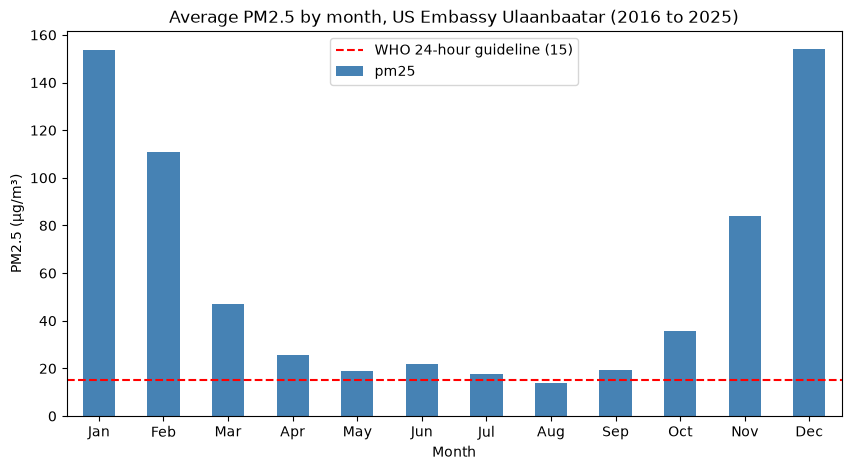

In [27]:
#5
monthly = us.groupby("month")["pm25"].mean()

ax = monthly.plot(kind="bar", figsize=(10, 5), color="steelblue")
fig = ax.get_figure()          # grab THIS chart's figure

ax.axhline(15, color="red", linestyle="--", label="WHO 24-hour guideline (15)")
ax.set_title("Average PM2.5 by month, US Embassy Ulaanbaatar (2016 to 2025)")
ax.set_xlabel("Month")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
fig.savefig("../figures/monthly_pm25.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
#6
before = df.groupby("station").size()
after = clean.groupby("station").size()
pd.DataFrame({"before": before, "after": after,
              "kept_%": (after / before * 100).round(0)})

,before,after,kept_%
station,,,
Amgalan,968,750,77.0
Baruun 4 zam,981,706,72.0
Bayankhoshuu,842,607,72.0
Bukhiin urguu,1001,721,72.0
Bumbugur,317,307,97.0
MNB,999,781,78.0
Nisekh,947,730,77.0
Tolgoit,942,720,76.0
US Embassy,3177,2111,66.0


In [29]:
#7
gaps.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=31)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2016,1,27,29,28,29,28,29,29,28,29,28,29
2017,29,15,0,9,29,28,20,18,23,28,22,7
2018,19,16,11,21,16,27,16,26,23,17,23,28
2019,27,26,29,27,28,26,27,19,25,25,28,24
2020,29,22,26,22,25,26,28,15,10,20,17,16
2021,27,17,0,0,0,0,0,0,0,0,28,29
2022,29,26,27,28,27,28,29,3,3,7,0,0
2023,0,0,0,0,0,0,0,0,0,12,25,27
2024,31,27,25,25,23,30,25,24,30,31,30,30


In [30]:
#8
winter = us[us["month"].isin([12, 1, 2])].copy()

# Label each winter by its January year (Dec 2018 belongs to winter 2019)
winter["winter"] = winter["year"].where(winter["month"] != 12, winter["year"] + 1)

counts = winter.groupby(["winter", "month"]).size().unstack(fill_value=0)
good_winters = counts[(counts >= 15).all(axis=1)].index

summary = (winter[winter["winter"].isin(good_winters)]
           .groupby("winter")["pm25"].agg(["mean", "count"]).round(1))
summary["period"] = ["Before ban" if w <= 2019 else "After ban" for w in summary.index]
summary

,mean,count,period
winter,,,
2017,164.3,73,Before ban
2019,188.4,81,Before ban
2020,138.7,75,After ban
2021,117.0,60,After ban
2022,142.6,84,After ban
2024,120.5,85,After ban
2025,99.7,82,After ban


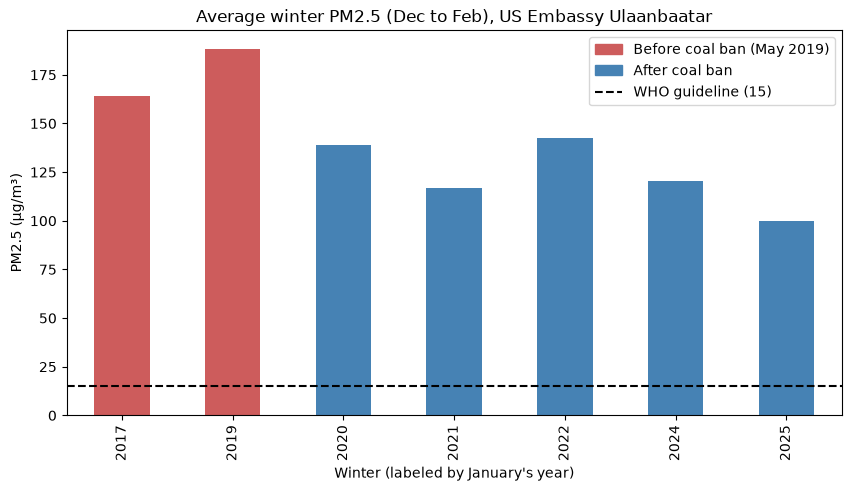

In [31]:
#9
from matplotlib.patches import Patch

colors = ["indianred" if p == "Before ban" else "steelblue" for p in summary["period"]]
ax = summary["mean"].plot(kind="bar", color=colors, figsize=(10, 5))
fig = ax.get_figure()          # grab THIS chart's figure

ax.axhline(15, color="black", linestyle="--")
ax.set_title("Average winter PM2.5 (Dec to Feb), US Embassy Ulaanbaatar")
ax.set_xlabel("Winter (labeled by January's year)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend(handles=[Patch(color="indianred", label="Before coal ban (May 2019)"),
                   Patch(color="steelblue", label="After coal ban"),
                   plt.Line2D([], [], color="black", linestyle="--", label="WHO guideline (15)")])

fig.savefig("../figures/winter_coal_ban.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
#10
summary.groupby("period")["mean"].mean().round(1)

period
After ban     123.7
Before ban    176.4
Name: mean, dtype: float64

In [33]:
#11
period = clean[clean["date"] < "2019-03-15"]
period = period[(period["group"] == "B") | (period["station"] == "US Embassy")]

wide = period.pivot_table(index="date", columns="station", values="pm25")
common = wide.dropna()

print("Total days:", len(wide))
print("Days where ALL stations have data:", len(common))

Total days: 1017
Days where ALL stations have data: 221


In [34]:
#12
winter_mask = common.index.month.isin([12, 1, 2])
summer_mask = common.index.month.isin([6, 7, 8])

compare = pd.DataFrame({
    "Winter (Dec to Feb)": common[winter_mask].mean(),
    "Summer (Jun to Aug)": common[summer_mask].mean(),
}).round(1).sort_values("Winter (Dec to Feb)")

compare["winter_x_summer"] = (compare.iloc[:, 0] / compare.iloc[:, 1]).round(1)
print("Winter days used:", winter_mask.sum(), "| Summer days used:", summer_mask.sum())
compare

Winter days used: 89 | Summer days used: 23


,Winter (Dec to Feb),Summer (Jun to Aug),winter_x_summer
station,,,
Bukhiin urguu,107.2,20.0,5.4
Amgalan,126.3,18.7,6.8
US Embassy,144.9,23.1,6.3
Nisekh,148.2,19.1,7.8
Baruun 4 zam,163.2,16.6,9.8
MNB,224.3,17.7,12.7
Tolgoit,228.6,17.4,13.1
Bayankhoshuu,319.5,37.6,8.5


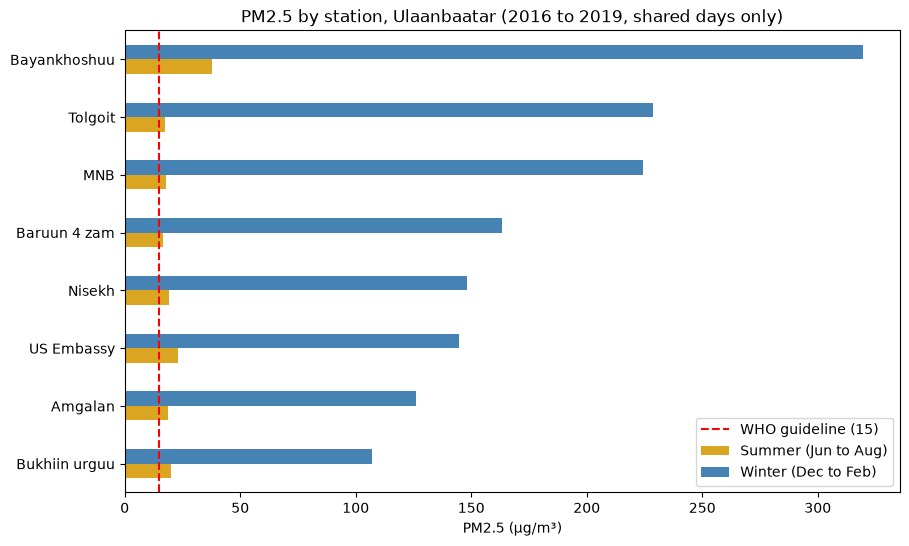

In [35]:
#13
ax = compare[["Summer (Jun to Aug)", "Winter (Dec to Feb)"]].plot(
    kind="barh", figsize=(10, 6), color=["goldenrod", "steelblue"])
fig = ax.get_figure()

ax.axvline(15, color="red", linestyle="--", label="WHO guideline (15)")
ax.set_title("PM2.5 by station, Ulaanbaatar (2016 to 2019, shared days only)")
ax.set_xlabel("PM2.5 (µg/m³)")
ax.set_ylabel("")
ax.legend()

fig.savefig("../figures/stations_winter_summer.png", dpi=150, bbox_inches="tight")
plt.show()

In [36]:
#14 
WHO, MNS = 15, 50

winter_ok = (gaps[[1, 2, 11, 12]] >= 15).all(axis=1)
good_years = winter_ok[winter_ok].index
good_years = good_years.drop(2021, errors="ignore")   # 2021 has only winter months left
health = (us[us["year"].isin(good_years)]
          .assign(over_who=lambda d: d["pm25"] > WHO,
                  over_mns=lambda d: d["pm25"] > MNS)
          .groupby("year")
          .agg(days_measured=("pm25", "size"),
               pct_over_who=("over_who", "mean"),
               pct_over_mns=("over_mns", "mean"),
               worst_day=("pm25", "max")))

health[["pct_over_who", "pct_over_mns"]] = (health[["pct_over_who", "pct_over_mns"]] * 100).round(0)
health["worst_day"] = health["worst_day"].round(0)
health

,days_measured,pct_over_who,pct_over_mns,worst_day
year,,,,
2018,243,72.0,34.0,366.0
2019,311,76.0,38.0,472.0
2020,256,68.0,28.0,285.0
2024,331,61.0,29.0,270.0


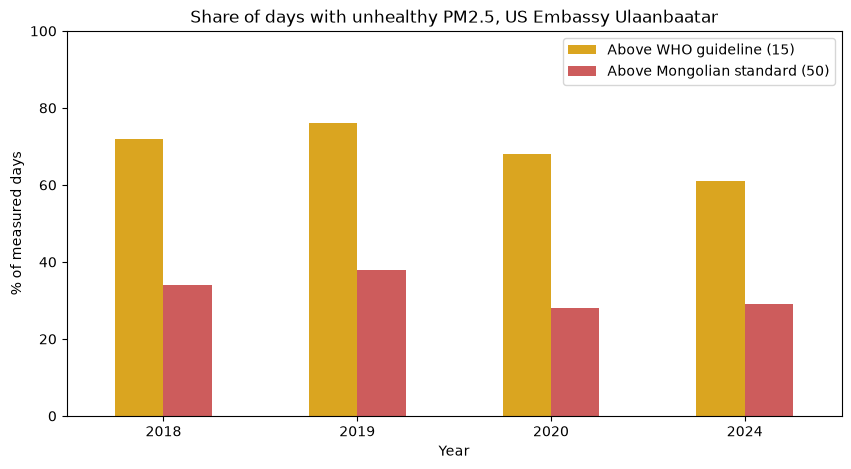

In [37]:
#15
ax = health[["pct_over_who", "pct_over_mns"]].plot(
    kind="bar", figsize=(10, 5), color=["goldenrod", "indianred"])
fig = ax.get_figure()

ax.set_title("Share of days with unhealthy PM2.5, US Embassy Ulaanbaatar")
ax.set_xlabel("Year")
ax.set_ylabel("% of measured days")
ax.set_ylim(0, 100)
ax.legend(["Above WHO guideline (15)", "Above Mongolian standard (50)"])
ax.tick_params(axis="x", rotation=0)

fig.savefig("../figures/unhealthy_days.png", dpi=150, bbox_inches="tight")
plt.show()

In [38]:
#16
check = (us[us["year"].isin(good_years)]
         .pivot_table(index="month", columns="year", values="pm25", aggfunc="median")
         .round(0))
check

year,2018,2019,2020,2024
month,,,,
1,131.0,220.0,192.0,150.0
2,79.0,118.0,97.0,90.0
3,24.0,52.0,36.0,29.0
4,16.0,26.0,24.0,17.0
5,20.0,16.0,13.0,10.0
6,20.0,17.0,15.0,10.0
7,11.0,10.0,11.0,18.0
8,7.0,12.0,10.0,9.0
9,19.0,18.0,17.0,11.0
